In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

DATASET_PATH = Path(
    r"D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels"
)

PB_PATH = DATASET_PATH / "PB"
PB_LABEL_PATH = DATASET_PATH / "PB_label"

sns.set_theme(style="whitegrid")

In [2]:
sample_file = next(PB_PATH.glob("*.jpg"))

sample_image = Image.open(sample_file).convert("L")
sample_array = np.array(sample_image)

print("Image:", sample_file.name)
print("Dimensions:", sample_array.shape)
print("Pixel data type:", sample_array.dtype)
print("Minimum intensity:", sample_array.min())
print("Maximum intensity:", sample_array.max())
print("Mean intensity:", sample_array.mean())
print("Standard deviation:", sample_array.std())

Image: SI383820211201123521_00009_20211201T125928.564000.jpg
Dimensions: (1024, 1280)
Pixel data type: uint8
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 127.33007583618163
Standard deviation: 63.43923041616788


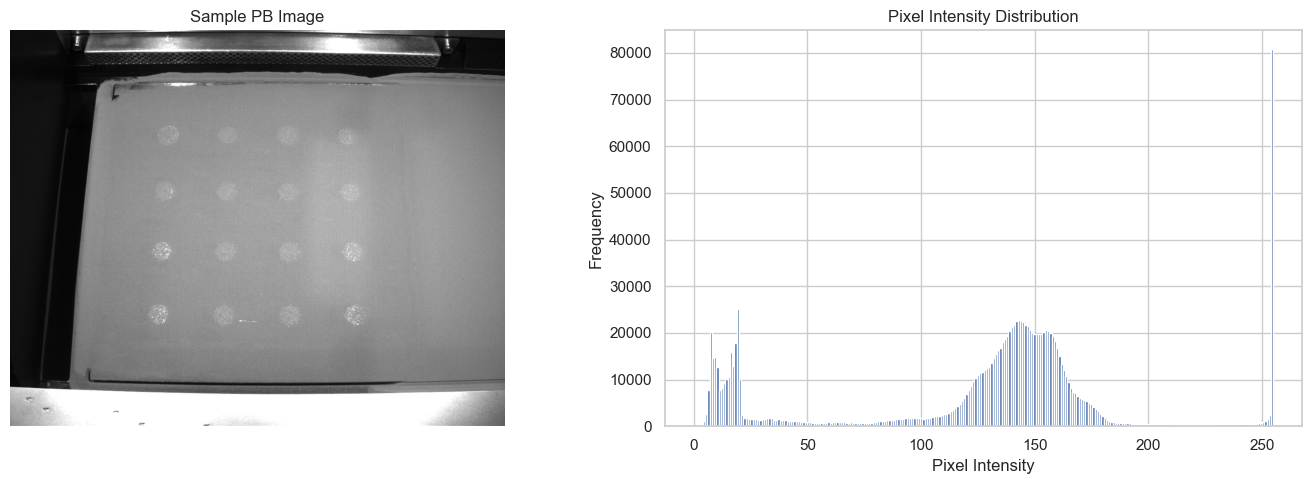

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(sample_array, cmap="gray")
axes[0].set_title("Sample PB Image")
axes[0].axis("off")

axes[1].hist(
    sample_array.ravel(),
    bins=256,
    range=(0, 255)
)

axes[1].set_title("Pixel Intensity Distribution")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [4]:
pb_intensity_stats = []

for file in tqdm(list(PB_PATH.glob("*.jpg"))):

    try:
        image = np.array(
            Image.open(file).convert("L")
        )

        pb_intensity_stats.append({
            "filename": file.name,
            "mean_intensity": image.mean(),
            "std_intensity": image.std(),
            "min_intensity": image.min(),
            "max_intensity": image.max(),
            "median_intensity": np.median(image)
        })

    except Exception as e:
        print(f"Error reading {file.name}: {e}")

pb_intensity_df = pd.DataFrame(pb_intensity_stats)

display(pb_intensity_df.head())

100%|██████████| 2638/2638 [01:24<00:00, 31.18it/s]


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
0,SI383820211201123521_00009_20211201T125928.564...,127.330076,63.439230,0,255,141.0
1,SI383820211201123521_00010_20211201T125941.618...,127.275117,63.370816,0,255,141.0
2,SI383820211201123521_00011_20211201T130024.623...,127.312411,63.462751,0,255,141.0
3,SI383820211201123521_00012_20211201T130037.654...,127.306372,63.392915,0,255,141.0
4,SI383820211201123521_00013_20211201T130118.809...,127.306552,63.465382,0,255,141.0


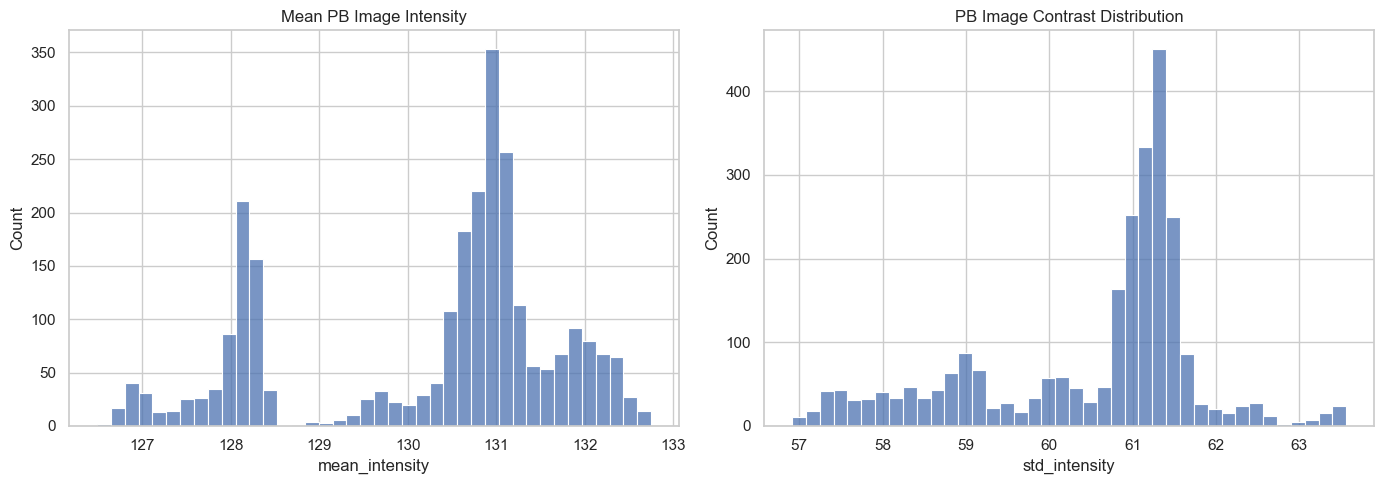

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=pb_intensity_df,
    x="mean_intensity",
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Mean PB Image Intensity")

sns.histplot(
    data=pb_intensity_df,
    x="std_intensity",
    bins=40,
    ax=axes[1]
)

axes[1].set_title("PB Image Contrast Distribution")

plt.tight_layout()
plt.show()

In [6]:
image_quality = []

for file in tqdm(list(PB_PATH.glob("*.jpg"))):

    try:
        with Image.open(file) as img:

            image_quality.append({
                "filename": file.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "file_size_kb": file.stat().st_size / 1024,
                "valid": True
            })

    except Exception as e:

        image_quality.append({
            "filename": file.name,
            "valid": False,
            "error": str(e)
        })

quality_df = pd.DataFrame(image_quality)

display(quality_df.head())

100%|██████████| 2638/2638 [00:00<00:00, 8146.34it/s]


,filename,width,height,mode,file_size_kb,valid
0,SI383820211201123521_00009_20211201T125928.564...,1280,1024,L,122.532227,True
1,SI383820211201123521_00010_20211201T125941.618...,1280,1024,L,120.929688,True
2,SI383820211201123521_00011_20211201T130024.623...,1280,1024,L,122.888672,True
3,SI383820211201123521_00012_20211201T130037.654...,1280,1024,L,121.561523,True
4,SI383820211201123521_00013_20211201T130118.809...,1280,1024,L,122.999023,True


In [7]:
print("Total images:", len(quality_df))
print("Valid images:", quality_df["valid"].sum())
print("Invalid images:", (~quality_df["valid"]).sum())

print("\nImage dimensions:")
print(quality_df.groupby(["width", "height"]).size())

print("\nFile size statistics:")
display(quality_df["file_size_kb"].describe())

Total images: 2638
Valid images: 2638
Invalid images: 0

Image dimensions:
width  height
1280   1024      2638
dtype: int64

File size statistics:


count    2638.000000
mean      126.886599
std         3.999812
min       118.106445
25%       124.263916
50%       125.744141
75%       128.200928
max       141.090820
Name: file_size_kb, dtype: float64

In [8]:
print("Darkest images:")
display(
    pb_intensity_df.nsmallest(10, "mean_intensity")
)

print("Brightest images:")
display(
    pb_intensity_df.nlargest(10, "mean_intensity")
)

Darkest images:


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
1054,SI383820240226095904_00063_20240226T115033.982...,126.486697,62.090579,0,255,139.0
1030,SI383820240226095904_00039_20240226T111600.802...,126.621741,62.336206,0,255,139.0
1029,SI383820240226095904_00038_20240226T111430.543...,126.659857,62.354715,0,255,139.0
1041,SI383820240226095904_00050_20240226T113147.144...,126.665258,61.969211,0,255,139.0
1053,SI383820240226095904_00062_20240226T114903.728...,126.692193,62.010521,0,255,139.0
1034,SI383820240226095904_00043_20240226T112146.903...,126.696325,62.111925,0,255,139.0
1033,SI383820240226095904_00042_20240226T112016.237...,126.700484,62.128485,0,255,139.0
1031,SI383820240226095904_00040_20240226T111722.969...,126.700921,62.305837,0,255,140.0
1052,SI383820240226095904_00061_20240226T114741.368...,126.716924,62.023957,0,255,139.0
1036,SI383820240226095904_00045_20240226T112439.067...,126.736854,62.071105,0,255,139.0


Brightest images:


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
1993,SI383820240318120348_00731_20240318T171134.771...,132.750655,61.301931,0,255,145.0
1994,SI383820240318120348_00732_20240318T171152.927...,132.724723,61.282581,0,255,145.0
1996,SI383820240318120348_00734_20240318T171229.026...,132.713158,61.264108,2,255,145.0
2001,SI383820240318120348_00739_20240318T171400.443...,132.711458,61.223751,0,255,145.0
2002,SI383820240318120348_00740_20240318T171418.651...,132.709203,61.223065,0,255,145.0
1995,SI383820240318120348_00733_20240318T171211.028...,132.707202,61.274696,1,255,145.0
1998,SI383820240318120348_00736_20240318T171306.229...,132.704958,61.235408,0,255,145.0
2000,SI383820240318120348_00738_20240318T171342.390...,132.704517,61.226598,0,255,145.0
1999,SI383820240318120348_00737_20240318T171324.381...,132.696453,61.226618,0,255,145.0
1997,SI383820240318120348_00735_20240318T171247.080...,132.669073,61.238932,0,255,145.0


In [9]:
import hashlib

def get_image_hash(file_path):

    with Image.open(file_path) as img:
        return hashlib.md5(
            img.convert("L").tobytes()
        ).hexdigest()


hash_records = []

for file in tqdm(list(PB_PATH.glob("*.jpg"))):

    hash_records.append({
        "filename": file.name,
        "hash": get_image_hash(file)
    })


hash_df = pd.DataFrame(hash_records)

duplicates = hash_df[
    hash_df.duplicated("hash", keep=False)
].sort_values("hash")

print("Total duplicate image files:", len(duplicates))

display(duplicates)

100%|██████████| 2638/2638 [00:15<00:00, 168.94it/s]

Total duplicate image files: 0


,filename,hash


In [12]:
OUTPUT_PATH = Path("outputs")
OUTPUT_PATH.mkdir(exist_ok=True)

pb_intensity_df.to_csv(
    OUTPUT_PATH / "pb_intensity_statistics.csv",
    index=False
)

quality_df.to_csv(
    OUTPUT_PATH / "pb_image_quality.csv",
    index=False
)

pb_annotations.to_csv(
    OUTPUT_PATH / "pb_annotations.csv",
    index=False
)

print("PB EDA results saved successfully.")

PB EDA results saved successfully.


In [11]:
pb_annotations = pd.read_csv("pb_annotations.csv")